## Course Careers

### Data Analytics Course


#### Python Portfolio Project

##### Step 1 - Load necessary libraries

In [97]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Setting so that the graphs open internally
%matplotlib inline

#Setting the overall Seaborn theme
sns.set_theme(style="whitegrid")

##### Step 2 - Load database and assign it to a Data Frame

In [98]:
# I'll use DF to name my Data Frame
df = sns.load_dataset("mpg")

##### Step 3 - Visualization of the first 5 rows

In [99]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


##### Step 4 - Understading the Data Types

In [100]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 35.9 KB


##### Question 1: Create a visual showing the relationship between horsepower and fuel economy.

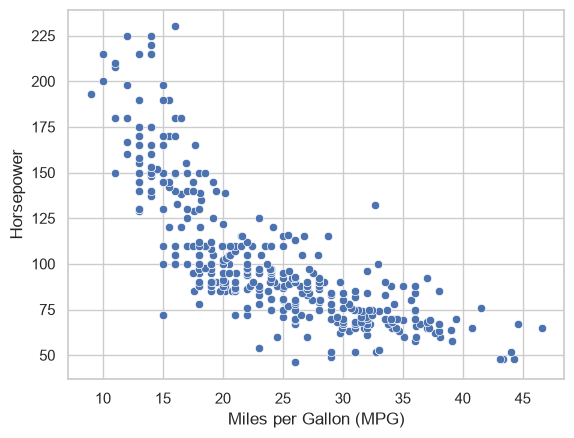

In [106]:
# Extracing the columns I need:

hp_vs_mpg = df[["mpg","horsepower"]].sort_values("horsepower")

# Creating a scatter plot

sns.scatterplot(data=hp_vs_mpg, x = "mpg", y = "horsepower")
plt.xlabel("Miles per Gallon (MPG)")
plt.ylabel("Horsepower")
plt.show()

##### Question 2: Create a table summarizing fuel economy by country of origin.

In [102]:
# I know I need to use a "groupby" and for this question I chose to use mean.

mpg_vs_country = (
    df.groupby("origin", as_index=False)["mpg"]
        .mean()
        .sort_values("mpg")
        .round(2)
        .rename(columns= {"origin": "Continent or Country", "mpg" : "Miles per Gallon (MPG)"})
)

mpg_vs_country

,Continent or Country,Miles per Gallon (MPG)
2,usa,20.08
0,europe,27.89
1,japan,30.45


##### Question 3: Create a visual showing how fuel economy has changed over time.

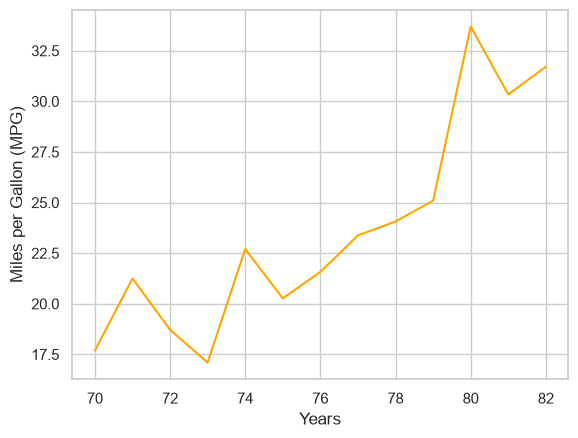

In [103]:
# According to the Line Plot Seaborn Documentation, available at:
# https://seaborn.pydata.org/generated/seaborn.lineplot.html
# "By default, the plot aggregates over multiple y values at each value of x 
# and shows an estimate of the central tendency and a confidence interval for that estimate."
# Meaning that cars with the same model_year will be aggregated.
# Creating the plot
sns.lineplot(data=df, x = "model_year", y = "mpg", errorbar=None, color="orange")
plt.xlabel("Years")
plt.ylabel("Miles per Gallon (MPG)")
plt.show()

##### Question 4: Create two other visuals or tables related to fuel economy.

###### Visual: Relationship between weight, horsepower and fuel economy.

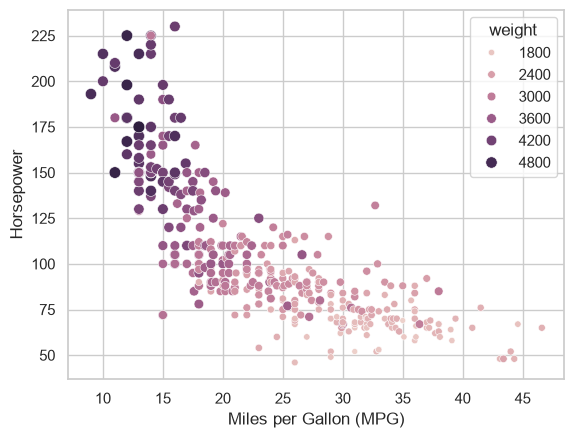

In [104]:
# Extracing the columns I need:

hp_and_weight_vs_mpg = df[["mpg","horsepower","weight"]].sort_values("mpg")

# Creating a scatter plot

sns.scatterplot(data=hp_and_weight_vs_mpg, x = "mpg", y = "horsepower", size = "weight", hue="weight")
plt.xlabel("Miles per Gallon (MPG)")
plt.ylabel("Horsepower")
plt.show()

###### Table: Top 5 cars with worst fuel economy.

In [109]:
top_5 = (df[["name", "mpg", "model_year"]]
    .sort_values("mpg")
    .head(5)
    .rename(columns= {"name": "Car Model", "mpg" : "Miles per Gallon (MPG)", "model_year": "Year"}))

top_5

,Car Model,Miles per Gallon (MPG),Year
28,hi 1200d,9.0,70
25,ford f250,10.0,70
26,chevy c20,10.0,70
67,mercury marquis,11.0,72
27,dodge d200,11.0,70


#### Observations

From the analysis you can conclude that weight, horsepower, the country of origin and the car model influentiate on the fuel economy (miles per gallon).

When doing an analysis on the relationship between horsepower and fuel economy, you see that cars with higher horsepower have a lower value of MPG, which makes sense, since these cars use more fuel to deliver the higher value of horsepower.
You can also see that the heavier the car the lower the value of MPG is.

When you look at it in a perspective of time, you can see that fuel efficiency has improved over the years because the value of MPG increases steadily.

And lastly, using this dataset, we can conclude that the top 5 cars with worse fuel economy are:
1. The International Harvester 1200D (hi 1200d) from 1970
2. Ford F250 from 1970
3. Chevy C20 from 1970
4. Mercury Marquis from 1972
5. Dodge D200 from 1970